# CV · INT8 PTQ и прунинг LeNet на MNIST

Главный вопрос — сколько точности сохраняет каждый метод при близком размере файла весов. В общем прогоне все варианты стартуют с одного FP32-чекпойнта. Измеряем top-1 на всех 10 000 примерах MNIST test и медиану прогретого CPU forward для batch 1 и 256.

**Результат.** Около 56 КиБ хватает для 98,52% у INT8 PTQ и 99,04% у LAMP с дообучением. Пять шагов LAMP без дообучения дали 76,17%. Плотный контроль с десятью эпохами дообучения достиг 99,28% при 179,23 КиБ.

[Исходный PTQ](../quantization/research/cnn_ptq/run.py) · [Прунинг без дообучения](../pruning/exp02.ipynb) · [Итеративный прунинг](../pruning/exp03.ipynb)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pruning").is_dir())
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})

## 1. Общий прогон

- FP32 LeNet + BatchNorm, 44 470 параметров. Все ветки используют [сохранённый чекпойнт PTQ](../quantization/research/cnn_ptq/artifacts/fp32/model.pt). PTQ калибруется на 512 примерах из train и конвертируется в oneDNN INT8.
- LAMP глобально удаляет каналы, защищая выходной слой. Доли 0,50–0,65 для one-shot дают файлы по обе стороны от INT8. Пять итераций на доле 0,60 сравниваются с таким же расписанием и двумя эпохами обучения на шаг. Плотный контроль получает те же 10 эпох, порядок train-батчей и перезапуски Adam с lr 0,0001.
- Единый размер — байты файла `torch.save(state_dict)` с одинаковым именем файла. Для загрузки требуется граф соответствующей архитектуры. Для каждой точки проверено совпадение logits на 64 изображениях после сохранения и загрузки.
- Задержка измерена на AMD Ryzen 5 5600 в PyTorch 2.5.1, один CPU-поток, медиана трёх прогретых раундов. Дообучение шло на GTX 1050 Ti. Для повторного запуска установите `torch-pruning==1.6.1`, предоставьте исходный чекпойнт и выставьте `rerun_cv = True`. Таблицы и график сохранены в ноутбуке. Для их пересчёта в Jupyter нужны pandas и matplotlib. Текстовые выводы относятся к сохранённому прогону.

In [2]:
rerun_cv = False

In [3]:
measured = {'checkpoint_sha256': '5a62bdc523480c70a458b924be9af254c75628312d46f145df66f648974ee75a',
 'torch': '2.5.1+cu121',
 'torch_pruning': '1.6.1',
 'cpu': 'AMD64 Family 25 Model 33 Stepping 2, AuthenticAMD',
 'threads': 1,
 'backend': 'onednn',
 'train_device': 'NVIDIA GeForce GTX 1050 Ti',
 'seed': 42,
 'calibration_examples': 512,
 'n_test': 10000,
 'steps': 5,
 'epochs_per_step': 2,
 'batch_train': 64,
 'learning_rate': 0.0001,
 'rows': [{'method': 'FP32',
           'ratio': 0.0,
           'ft_epochs': 0,
           'parameters': 44470,
           'compression_stage_s': 0.0,
           'correct': 9855,
           'accuracy_pct': 98.55,
           'fp_correct_ptq_wrong': 0,
           'fp_wrong_ptq_correct': 0,
           'state_dict_bytes': 183530,
           'cpu_ms_batch_1': {'median': 0.28404460000092513,
                              'rounds': [0.28404460000092513, 0.34297719999813125, 0.28378560000055586]},
           'cpu_ms_batch_256': {'median': 8.6395000002085,
                                'rounds': [8.6395000002085, 8.600509999814676, 8.762399999977788]}},
          {'method': 'PTQ INT8 per-tensor MinMax',
           'ratio': 0.0,
           'ft_epochs': 0,
           'parameters': None,
           'compression_stage_s': 0.12172610000197892,
           'correct': 9849,
           'accuracy_pct': 98.49,
           'fp_correct_ptq_wrong': 9,
           'fp_wrong_ptq_correct': 3,
           'state_dict_bytes': 52000,
           'cpu_ms_batch_1': {'median': 0.5967409999720985,
                              'rounds': [0.6002614999852085, 0.5967409999720985, 0.5882100000235368]},
           'cpu_ms_batch_256': {'median': 4.1191100001015,
                                'rounds': [4.128070000115258, 4.107570000269334, 4.1191100001015]}},
          {'method': 'PTQ INT8 per-channel MinMax',
           'ratio': 0.0,
           'ft_epochs': 0,
           'parameters': None,
           'compression_stage_s': 0.06431529999827035,
           'correct': 9852,
           'accuracy_pct': 98.52,
           'fp_correct_ptq_wrong': 4,
           'fp_wrong_ptq_correct': 1,
           'state_dict_bytes': 57774,
           'cpu_ms_batch_1': {'median': 0.5850849999987986,
                              'rounds': [0.6165895000049203, 0.5746970000109286, 0.5850849999987986]},
           'cpu_ms_batch_256': {'median': 4.211485000087122,
                                'rounds': [4.25990500007174, 4.089979999844218, 4.211485000087122]}},
          {'method': 'PTQ INT8 per-channel Histogram',
           'ratio': 0.0,
           'ft_epochs': 0,
           'parameters': None,
           'compression_stage_s': 0.16299000000071828,
           'correct': 9852,
           'accuracy_pct': 98.52,
           'fp_correct_ptq_wrong': 4,
           'fp_wrong_ptq_correct': 1,
           'state_dict_bytes': 57774,
           'cpu_ms_batch_1': {'median': 0.5956430000151158,
                              'rounds': [0.5872760000056587, 0.5956430000151158, 0.6017580000116141]},
           'cpu_ms_batch_256': {'median': 4.1053550001379335,
                                'rounds': [4.144600000108767, 4.096600000048056, 4.1053550001379335]}},
          {'method': 'LAMP one-shot',
           'ratio': 0.5,
           'ft_epochs': 0,
           'parameters': 16767,
           'compression_stage_s': 0.026093199998285854,
           'correct': 8744,
           'accuracy_pct': 87.44,
           'fp_correct_ptq_wrong': 1143,
           'fp_wrong_ptq_correct': 32,
           'state_dict_bytes': 72682,
           'cpu_ms_batch_1': {'median': 0.2811251000021002,
                              'rounds': [0.2800683999994362, 0.2811251000021002, 0.2871677000002819]},
           'cpu_ms_batch_256': {'median': 8.523849999983213,
                                'rounds': [8.523849999983213, 8.47317000007024, 8.868520000032731]}},
          {'method': 'LAMP one-shot',
           'ratio': 0.55,
           'ft_epochs': 0,
           'parameters': 14649,
           'compression_stage_s': 0.0075980000001436565,
           'correct': 8021,
           'accuracy_pct': 80.21,
           'fp_correct_ptq_wrong': 1866,
           'fp_wrong_ptq_correct': 32,
           'state_dict_bytes': 64234,
           'cpu_ms_batch_1': {'median': 0.28537019999930635,
                              'rounds': [0.2916963999996369, 0.2768220999969344, 0.28537019999930635]},
           'cpu_ms_batch_256': {'median': 8.68268000012904,
                                'rounds': [8.40267000021413, 8.68268000012904, 9.01518999999098]}},
          {'method': 'LAMP one-shot',
           'ratio': 0.6,
           'ft_epochs': 0,
           'parameters': 12647,
           'compression_stage_s': 0.006417600001441315,
           'correct': 7775,
           'accuracy_pct': 77.75,
           'fp_correct_ptq_wrong': 2122,
           'fp_wrong_ptq_correct': 42,
           'state_dict_bytes': 56298,
           'cpu_ms_batch_1': {'median': 0.3069543999990856,
                              'rounds': [0.2958768999997119, 0.3203603999972984, 0.3069543999990856]},
           'cpu_ms_batch_256': {'median': 8.493110000199522,
                                'rounds': [8.528690000093775, 8.493110000199522, 8.46640000017942]}},
          {'method': 'LAMP one-shot',
           'ratio': 0.65,
           'ft_epochs': 0,
           'parameters': 10953,
           'compression_stage_s': 0.007782600001519313,
           'correct': 7069,
           'accuracy_pct': 70.69,
           'fp_correct_ptq_wrong': 2834,
           'fp_wrong_ptq_correct': 48,
           'state_dict_bytes': 49450,
           'cpu_ms_batch_1': {'median': 0.32278930000029504,
                              'rounds': [0.32278930000029504, 0.3712497999986226, 0.3117433000006713]},
           'cpu_ms_batch_256': {'median': 8.684830000129296,
                                'rounds': [9.092840000084834, 8.684830000129296, 8.335470000019995]}},
          {'method': 'LAMP iterative',
           'ratio': 0.6,
           'ft_epochs': 0,
           'parameters': 12894,
           'compression_stage_s': 0.01827009999760776,
           'correct': 7617,
           'accuracy_pct': 76.17,
           'fp_correct_ptq_wrong': 2266,
           'fp_wrong_ptq_correct': 28,
           'state_dict_bytes': 57322,
           'cpu_ms_batch_1': {'median': 0.2818493999984639,
                              'rounds': [0.2818493999984639, 0.28082419999918784, 0.28459660000225995]},
           'cpu_ms_batch_256': {'median': 8.612539999739965,
                                'rounds': [8.63162999994529, 8.612539999739965, 8.611810000002151]}},
          {'method': 'LAMP iterative + FT',
           'ratio': 0.6,
           'ft_epochs': 10,
           'parameters': 12894,
           'compression_stage_s': 32.09417690000191,
           'correct': 9904,
           'accuracy_pct': 99.04,
           'fp_correct_ptq_wrong': 27,
           'fp_wrong_ptq_correct': 76,
           'state_dict_bytes': 57322,
           'cpu_ms_batch_1': {'median': 0.2873414999994566,
                              'rounds': [0.2790612999997393, 0.30326549999881536, 0.2873414999994566]},
           'cpu_ms_batch_256': {'median': 8.58711000000767,
                                'rounds': [8.752340000137337, 8.54369000007864, 8.58711000000767]}},
          {'method': 'Dense + FT',
           'ratio': 0.0,
           'ft_epochs': 10,
           'parameters': 44470,
           'compression_stage_s': 29.577216800000315,
           'correct': 9928,
           'accuracy_pct': 99.28,
           'fp_correct_ptq_wrong': 13,
           'fp_wrong_ptq_correct': 86,
           'state_dict_bytes': 183530,
           'cpu_ms_batch_1': {'median': 0.2811957000012626,
                              'rounds': [0.2902493000001414, 0.2800128999988374, 0.2811957000012626]},
           'cpu_ms_batch_256': {'median': 8.708069999920554,
                                'rounds': [8.708069999920554, 8.676479999849107, 9.321640000052867]}}]}

In [4]:
def run_cv(root):
    import copy
    import hashlib
    import os
    import platform
    import sys
    import tempfile
    from time import perf_counter

    from importlib.metadata import version

    import torch
    import torch_pruning as tp
    from torch.nn import functional as F
    from torch.utils.data import DataLoader, TensorDataset

    source = root / "quantization/research/cnn_ptq"
    sys.path.insert(0, str(source))
    from run import (CALIBRATION_SIZE, ENGINE, SEED, HistogramObserver, LeNet,
                     MinMaxObserver, evaluate, load_mnist, make_quantized)

    torch.manual_seed(SEED)
    torch.set_num_threads(1)
    torch.backends.quantized.engine = ENGINE
    train_x, train_y = load_mnist(train=True)
    test_x, test_y = load_mnist(train=False)
    checkpoint = source / "artifacts/fp32/model.pt"
    base = LeNet().eval()
    base.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))

    train_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if train_device.type == "cuda":
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    indices = torch.randperm(len(train_x), generator=torch.Generator().manual_seed(SEED))
    calibration = train_x[indices[:CALIBRATION_SIZE]]
    example = torch.zeros(1, 1, 28, 28)
    steps, epochs, learning_rate = 5, 2, 1e-4

    def prune(model, ratio, prune_steps):
        return tp.pruner.MagnitudePruner(
            model, example, importance=tp.importance.LAMPImportance(p=2),
            global_pruning=True, pruning_ratio=ratio, iterative_steps=prune_steps,
            ignored_layers=[model.fc3],
        )

    def make_pruned(ratio, prune_steps, tune):
        started = perf_counter()
        model = copy.deepcopy(base)
        pruner = prune(model, ratio, prune_steps) if ratio else None
        loader = DataLoader(
            TensorDataset(train_x, train_y), batch_size=64, shuffle=True,
            generator=torch.Generator().manual_seed(SEED),
        ) if tune else None
        for step in range(prune_steps):
            if pruner is not None:
                model.cpu().eval()
                pruner.step()
            if tune:
                model.to(train_device).train()
                optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
                for _ in range(epochs):
                    for x, y in loader:
                        optimizer.zero_grad(set_to_none=True)
                        F.cross_entropy(model(x.to(train_device)), y.to(train_device)).backward()
                        optimizer.step()
                print(f"ratio={ratio:g}; fine-tune step {step + 1}/{prune_steps}", flush=True)
        return model.cpu().eval(), perf_counter() - started

    rows = []
    # Use the same basename for all zip archives (it affects torch.save overhead).
    with tempfile.TemporaryDirectory(dir=root / "results") as directory:
        from pathlib import Path
        path = Path(directory) / "model.pt"

        def record(name, model, ratio=0.0, ft_epochs=0, elapsed=0.0):
            flags, measured = evaluate(model, test_x, test_y, path, fp_correct)
            correct_after_reload = copy.deepcopy(model)
            correct_after_reload.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
            with torch.inference_mode():
                torch.testing.assert_close(model(test_x[:64]), correct_after_reload(test_x[:64]),
                                           rtol=0, atol=0)
            row = {"method": name, "ratio": ratio, "ft_epochs": ft_epochs,
                   "parameters": (sum(p.numel() for p in model.parameters())
                                  if not name.startswith("PTQ") else None),
                   "compression_stage_s": elapsed, **measured}
            rows.append(row)
            print(name, ratio, row["accuracy_pct"], row["state_dict_bytes"], flush=True)
            return flags

        fp_correct = None
        fp_correct = record("FP32", base)
        for name, recipe in (
            ("PTQ INT8 per-tensor MinMax", (False, MinMaxObserver)),
            ("PTQ INT8 per-channel MinMax", (True, MinMaxObserver)),
            ("PTQ INT8 per-channel Histogram", (True, HistogramObserver)),
        ):
            started = perf_counter()
            with torch.no_grad():
                quantized = make_quantized(base, calibration, *recipe)
            record(name, quantized, elapsed=perf_counter() - started)

        for ratio in (0.50, 0.55, 0.60, 0.65):
            model, seconds = make_pruned(ratio, 1, False)
            record("LAMP one-shot", model, ratio, elapsed=seconds)

        ratio = 0.60
        model, seconds = make_pruned(ratio, steps, False)
        record("LAMP iterative", model, ratio, elapsed=seconds)
        model, seconds = make_pruned(ratio, steps, True)
        record("LAMP iterative + FT", model, ratio, steps * epochs, seconds)
        model, seconds = make_pruned(0.0, steps, True)
        record("Dense + FT", model, 0.0, steps * epochs, seconds)

    return {"checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
            "torch": torch.__version__, "torch_pruning": version("torch-pruning"),
            "cpu": os.environ.get("PROCESSOR_IDENTIFIER", platform.processor()),
            "threads": torch.get_num_threads(), "backend": ENGINE,
            "train_device": (torch.cuda.get_device_name() if train_device.type == "cuda" else "CPU"),
            "seed": SEED, "calibration_examples": CALIBRATION_SIZE,
            "n_test": len(test_y), "steps": steps, "epochs_per_step": epochs,
            "batch_train": 64, "learning_rate": learning_rate, "rows": rows}


if rerun_cv:
    measured = run_cv(root)

In [5]:
cv = pd.DataFrame(measured["rows"])
fp = cv.iloc[0]
cv["size_kib"] = cv["state_dict_bytes"] / 1024
cv["compression"] = fp["state_dict_bytes"] / cv["state_dict_bytes"]
cv["delta_acc_pp"] = cv["accuracy_pct"] - fp["accuracy_pct"]
cv["delta_vs_dense_ft_pp"] = (cv["accuracy_pct"] -
    cv.loc[cv["method"].eq("Dense + FT"), "accuracy_pct"].iat[0]).where(cv["ft_epochs"].gt(0))
for batch in (1, 256):
    cv[f"b{batch}_ms"] = cv[f"cpu_ms_batch_{batch}"].map(lambda item: item["median"])
columns = ["method", "ratio", "ft_epochs", "accuracy_pct", "delta_acc_pp",
           "delta_vs_dense_ft_pp", "size_kib", "compression", "b1_ms", "b256_ms"]
display(cv[columns].round(3))

,method,ratio,ft_epochs,accuracy_pct,delta_acc_pp,delta_vs_dense_ft_pp,size_kib,compression,b1_ms,b256_ms
0,FP32,0.00,0,98.55,0.00,NaN,179.229,1.000,0.284,8.640
1,PTQ INT8 per-tensor MinMax,0.00,0,98.49,-0.06,NaN,50.781,3.529,0.597,4.119
2,PTQ INT8 per-channel MinMax,0.00,0,98.52,-0.03,NaN,56.420,3.177,0.585,4.211
3,PTQ INT8 per-channel Histogram,0.00,0,98.52,-0.03,NaN,56.420,3.177,0.596,4.105
4,LAMP one-shot,0.50,0,87.44,-11.11,NaN,70.979,2.525,0.281,8.524
5,LAMP one-shot,0.55,0,80.21,-18.34,NaN,62.729,2.857,0.285,8.683
6,LAMP one-shot,0.60,0,77.75,-20.80,NaN,54.979,3.260,0.307,8.493
7,LAMP one-shot,0.65,0,70.69,-27.86,NaN,48.291,3.711,0.323,8.685
8,LAMP iterative,0.60,0,76.17,-22.38,NaN,55.979,3.202,0.282,8.613
9,LAMP iterative + FT,0.60,10,99.04,0.49,-0.24,55.979,3.202,0.287,8.587


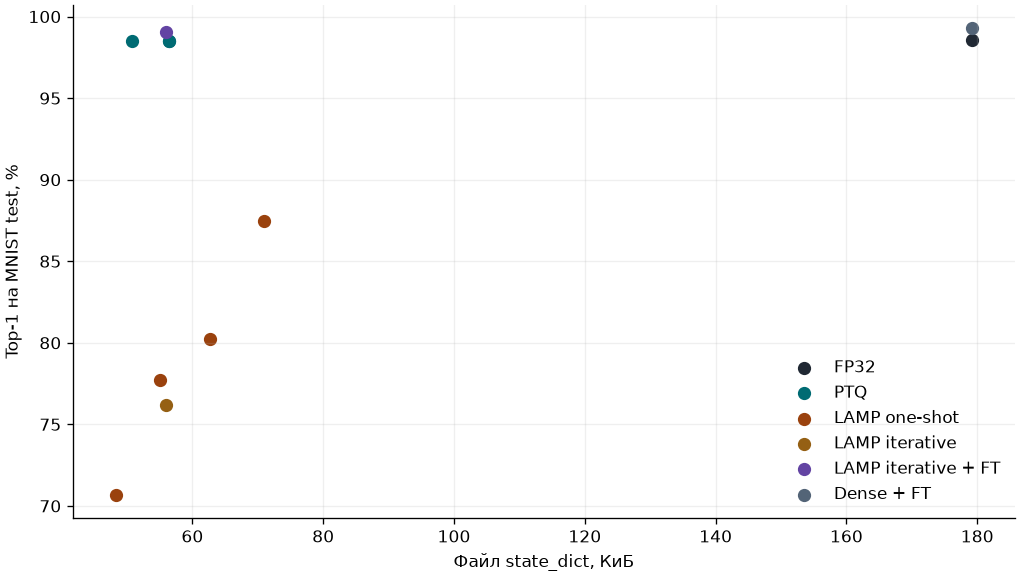

In [6]:
colors = {'FP32': '#202833', 'FP': '#202833', 'PTQ': '#006b73', 'LAMP one-shot': '#9a420e', 'LAMP iterative': '#956014', 'LAMP iterative + FT': '#6344a3', 'Dense + FT': '#536477', 'Magnitude MLP ×5': '#9a420e', 'RTN W8 MLP': '#006b73', 'RTN W4 MLP': '#117d90', 'RTN W4 all block Linear': '#426cb1'}
cv["series"] = cv["method"].str.replace(r"^PTQ.*", "PTQ", regex=True)
fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
for series, rows in cv.groupby("series", sort=False):
    ax.scatter(rows["size_kib"], rows["accuracy_pct"], color=colors[series], label=series, s=48)
ax.set(xlabel="Файл state_dict, КиБ", ylabel="Top-1 на MNIST test, %")
ax.grid(alpha=.2)
ax.legend(frameon=False, loc="lower right")
plt.show()

In [7]:
comparison = cv.set_index(["method", "ratio"])
ptq = comparison.loc[("PTQ INT8 per-channel MinMax", 0.0)]
short_list = comparison.loc[[
    ("PTQ INT8 per-channel MinMax", 0.0), ("LAMP one-shot", .60),
    ("LAMP iterative", .60), ("LAMP iterative + FT", .60), ("Dense + FT", 0.0)
], ["state_dict_bytes", "accuracy_pct", "ft_epochs", "b1_ms", "b256_ms"]].copy()
short_list["разница размера с PTQ, %"] = 100 * (short_list["state_dict_bytes"] /
                                               ptq["state_dict_bytes"] - 1)
display(short_list.round(3))

,,state_dict_bytes,accuracy_pct,ft_epochs,b1_ms,b256_ms,"разница размера с PTQ, %"
method,ratio,,,,,,
PTQ INT8 per-channel MinMax,0.0,57774,98.52,0,0.585,4.211,0.000
LAMP one-shot,0.6,56298,77.75,0,0.307,8.493,-2.555
LAMP iterative,0.6,57322,76.17,0,0.282,8.613,-0.782
LAMP iterative + FT,0.6,57322,99.04,10,0.287,8.587,-0.782
Dense + FT,0.0,183530,99.28,10,0.281,8.708,217.669


При практически одинаковом размере файла — 57 774 и 57 322 байта — переход от INT8 PTQ к LAMP без дообучения приводит к разнице −22,35 п. п. В LAMP дообучение восстанавливает 22,87 п. п. при том же размере. После восстановления LAMP опережает PTQ на 0,52 п. п. и отстаёт от плотной модели с таким же бюджетом обучения на 0,24 п. п. LAMP переоценивает важность каналов на каждом шаге, поэтому fine-tuning может изменить набор удалённых каналов. Прогон охватывает один чекпойнт и один seed.

CPU-замер относится к реализованным графам. Per-channel MinMax занял около 0,59 мс при batch 1 и 4,21 мс при batch 256, FP32 — 0,28 и 8,64 мс. У дообученного LAMP на этих батчах около 0,29 и 8,59 мс.

## 2. Исходные серии

Для каждого ряда прунинга считаем Δ accuracy к базовой строке той же стратегии при ratio 0. В d03 эта строка уже включает дообучение. Исходный FP32 до дообучения в d03 — 98,09%. Старый `size_mb` означает оценку `число параметров × 4`, выраженную в МиБ. Исходные PTQ-замеры содержат реальный файл весов. Исторические задержки относятся к разным средам.

In [8]:
logs = root / "pruning/logs"
files = {
    "d01 · маски": "all_strategies.csv",
    "d02 · каналы, без FT": "d02/all_strategies_structured.csv",
    "d03 · каналы, с FT": "d03/all_strategies_iterative.csv",
}
source_rows = []
for series, filename in files.items():
    table = pd.read_csv(logs / filename).dropna(subset=["accuracy"])
    reference = table.loc[table["ratio"].eq(0)].set_index("strategy")["accuracy"]
    table["delta_pp"] = table["accuracy"] - table["strategy"].map(reference)
    source_rows.append(table.assign(series=series))
historical_pruning = pd.concat(source_rows, ignore_index=True)
display(historical_pruning.loc[historical_pruning["ratio"].isin([0.0, 0.6, 0.7]),
    ["series", "strategy", "ratio", "accuracy", "delta_pp", "params", "size_mb"]].round(3))

,series,strategy,ratio,accuracy,delta_pp,params,size_mb
0,d01 · маски,unstructured_l1,0.0,98.91,0.00,44470,0.170
6,d01 · маски,unstructured_l1,0.6,98.09,-0.82,44470,0.170
7,d01 · маски,unstructured_l1,0.7,97.52,-1.39,44470,0.170
8,d01 · маски,unstructured_random,0.0,98.91,0.00,44470,0.170
14,d01 · маски,unstructured_random,0.6,11.35,-87.56,44470,0.170
15,d01 · маски,unstructured_random,0.7,11.35,-87.56,44470,0.170
16,"d02 · каналы, без FT",structured_magnitude,0.0,98.09,0.00,44470,0.170
22,"d02 · каналы, без FT",structured_magnitude,0.6,46.29,-51.80,6999,0.027
23,"d02 · каналы, без FT",structured_magnitude,0.7,22.30,-75.79,3712,0.014
24,"d02 · каналы, без FT",structured_bn,0.0,98.09,0.00,44470,0.170


In [9]:
historical_file = root / "quantization/research/cnn_ptq/artifacts/results.json"
if historical_file.is_file():
    import json
    historical_ptq = pd.DataFrame.from_dict(
        json.loads(historical_file.read_text(encoding="utf-8"))["results"], orient="index"
    )
    display(historical_ptq[["accuracy_pct", "state_dict_bytes"]])
else:
    print("Историческая серия PTQ описана в quantization/research/quantization_results.md.")

,accuracy_pct,state_dict_bytes
fp32,98.55,183530
int8_tensor_minmax,98.49,52000
int8_channel_minmax,98.52,57774
int8_channel_histogram,98.52,57774


## 3. Степень эквивалентности

| Критерий | Исторические серии | Общий прогон |
|---|---|---|
| Чекпойнт и тест | LeNet + BN, MNIST, разные веса | Одни FP32-веса, одна нормализация, весь MNIST test |
| Охват | PTQ квантует пять слоёв. LAMP защищает выход | Сохранён охват каждого метода |
| Бюджет обучения | PTQ и разовый структурный прунинг без FT; итеративная серия с FT | Есть пара без FT, пара с одинаковым расписанием LAMP и плотный FT-контроль |
| Размер | Оценка тензоров против файла весов | Один формат сериализации, разница размера в паре PTQ и итеративного LAMP — 0,78% |
| Задержка | Разные устройства и процедуры | Один CPU, поток, батчи и процедура |

[Сводка для презентации](comparison_notes.md)